# Week 4: Linear Regression

https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-18-linear-regression/lesson-18-linear-regression.html

In [4]:
# Load packages
import os
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Load data
fp = os.path.join('..','eds220-discussion-sections','data','55_Hare_Data_2012.txt')
hares = pd.read_csv(fp)

In [5]:
# Check data loaded
hares.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [ ]:
# Display column info
hares.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [ ]:
# Change date column to datetime
hares['date'] = pd.to_datetime(hares['date'])
print(hares['date'].dtype)

datetime64[ns]


## Examine the hares' age data


In [ ]:
# Examine unique values and counts in age column
# Metadata - should jsut have a (adult), j (juvenile), (mort (mortality) - but none exist)
pd.DataFrame(hares['age'].value_counts(dropna=False))

,count
age,
NaN,2111
A,564
J,267
a,183
j,128
1/2/2013,21
1/4/2013,21
3/4/2013,18
1,12


In [9]:
# Update age values to juvenile and adult for observations where 'a' and 'j' are included
hares.loc[hares['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
hares.loc[hares['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'

# Filter for confirmed observations of juvenile and adult hares
hares_juv_adult = hares[hares['age'].isin(['juvenile', 'adult'])].copy()
print("Number of juvenile and adult hare observations (captures):", len(hares_juv_adult))

Number of juvenile and adult hare observations (captures): 1155


In [ ]:
# Create new column - extract year in which each observation happened
hares_juv_adult['year'] = hares_juv_adult['date'].dt.year

# Count observations per year and age, then move age values into columns
# .unstack() is a pivot wider equivalent
hares_per_year = hares_juv_adult.groupby(['year', 'age']).size().unstack()
hares_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


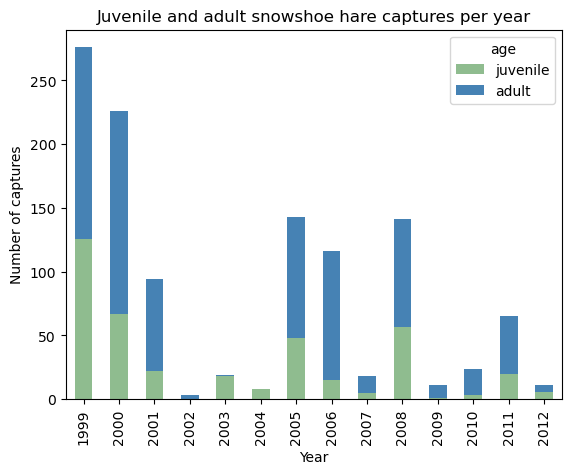

In [ ]:
# Plot hares per year
hares_per_year[['juvenile', 'adult']].plot(kind='bar',                # Columns in stacking order
                                         stacked=True,                # Stack the bars
                                         color=['#8FBC8F', '#4682B4'],
                                         title='Juvenile and adult snowshoe hare captures per year',
                                         xlabel='Year',
                                         ylabel='Number of captures');

# No trap method/effort indicated, so conclusions on population dynamics are difficult

## Plotting with matplotlib

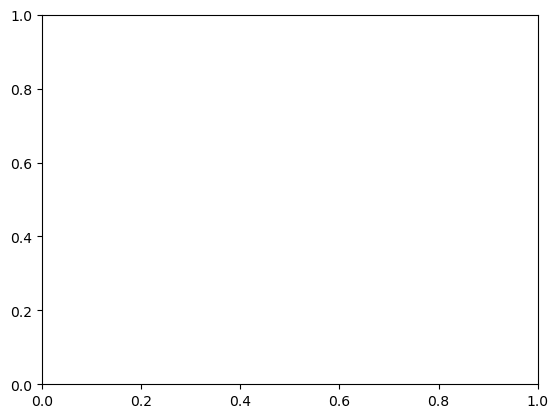

In [ ]:
# Initialize empty figure (fig) and axes (ax) - returns fig and single axis
fig, ax = plt.subplots()

# Display figure
plt.show()

General matplotlib syntax:

```{python}
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Plot df on the ax axes
df.plot(ax=ax,  # Add plot to axes
        ...)    # Other arguments for plot function

# Display figure
plt.show()
```

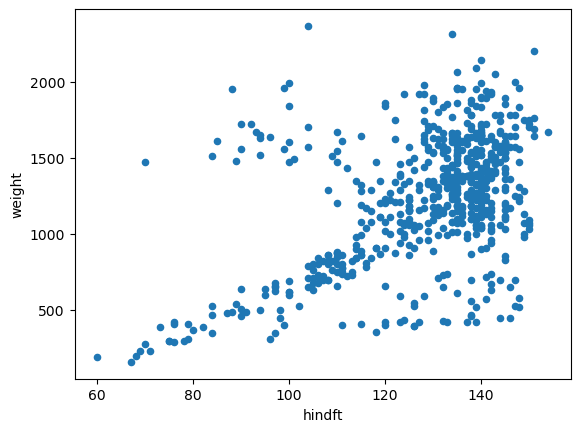

In [15]:
# Plot hares data
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add scatter plot of hares' data to our figure's axes
hares_juv_adult.plot(kind='scatter', x='hindft', y='weight', ax=ax)

# Display figure
plt.show()

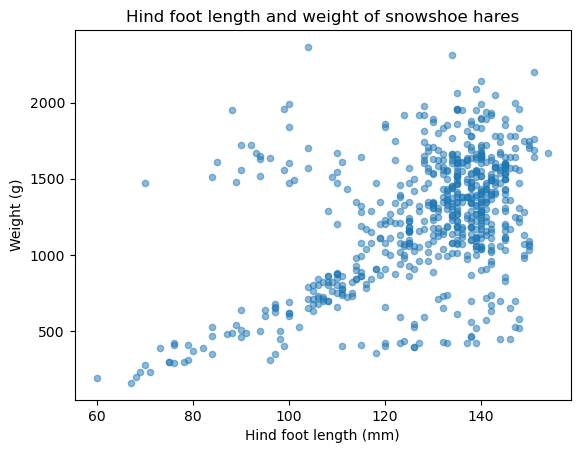

In [17]:
# Adding Customizations

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add data to axes
hares_juv_adult.plot(kind='scatter', 
                   x='hindft', 
                   y='weight', 
                   alpha=0.5,     # Adjust transparency
                   ax=ax)         # Add plot to axes

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display figure
plt.show()

## Linear regression

For our analysis we want to investigate possible relations between hind foot length and weight for juvenile hares.

Number of juvenile hare captures with hind foot and weight measurements: 265


<Axes: xlabel='hindft', ylabel='weight'>

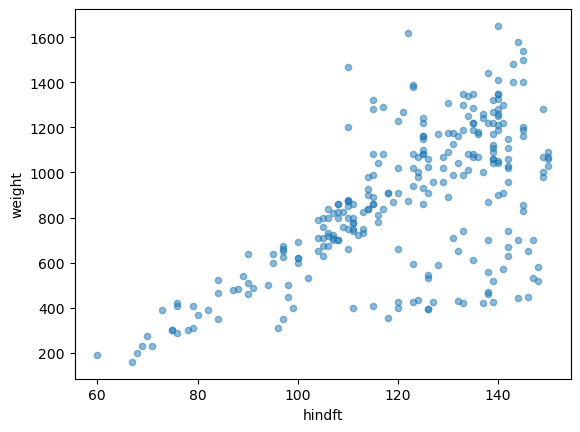

In [18]:
# Subset juvenile hares and drop rows missing hind foot or weight measurements
juveniles_weight_hindft = hares_juv_adult[hares_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

print("Number of juvenile hare captures with hind foot and weight measurements:", len(juveniles_weight_hindft))
juveniles_weight_hindft.plot.scatter(x='hindft', y='weight', alpha=0.5)

In [19]:
# Fit model: weight explained by hind foot length
model = smf.ols('weight ~ hindft', data=juveniles_weight_hindft).fit()

In [ ]:
# Display model parameters - coefficients
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [21]:
# Retrieve intercept and slope coefficients as variables
intercept = model.params['Intercept']
print("y-intercept:", intercept)

slope = model.params['hindft']
print("Slope:", slope)

y-intercept: -352.77198564640645
Slope: 10.092239638623006


In [ ]:
# Display coefficient of determination - R^2 (R^2 = 1 is a perfect fit, 0 is a (very) bad fit)
# We interpret it as the proportion of variance in the response that is explained by the least
#   squares line with the predictor variable.
print("R^2:", model.rsquared)

R^2: 0.3871164783665738


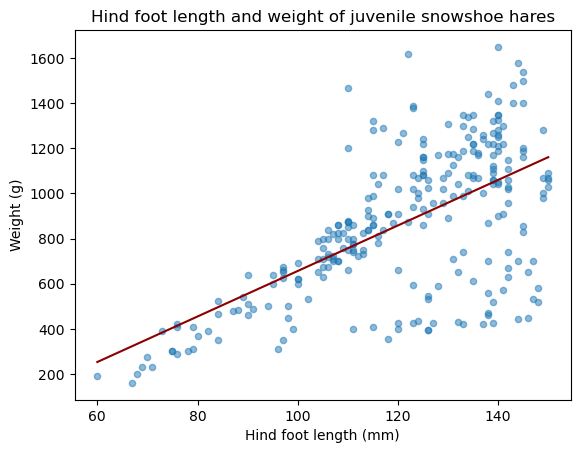

In [23]:
# Add regression line

# Smallest and largest hind foot lengths
x_start = juveniles_weight_hindft['hindft'].min()
x_end = juveniles_weight_hindft['hindft'].max()

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add data to axes
juveniles_weight_hindft.plot(kind='scatter', 
                             x='hindft', 
                             y='weight', 
                             alpha=0.5,     # Adjust transparency
                             ax=ax)         # Add plot to axes

# Add regression line to axes
ax.plot([x_start, x_end], 
        [intercept + slope*x_start, intercept + slope*x_end],
        color='darkred')

# Update axes
ax.set_title('Hind foot length and weight of juvenile snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display figure
plt.show()

## Checking the residuals

In [ ]:
# View residuals values
model.resid

108    -523.850209
109    -609.864845
110    -655.510522
111    -397.835573
112    -549.403647
           ...    
3355    -46.820937
3359    117.625625
3360    117.625625
3367   -276.175259
3369    -37.189895
Length: 265, dtype: float64

<Axes: title={'center': 'Distribution of residuals'}, xlabel='Residual (g)', ylabel='Frequency'>

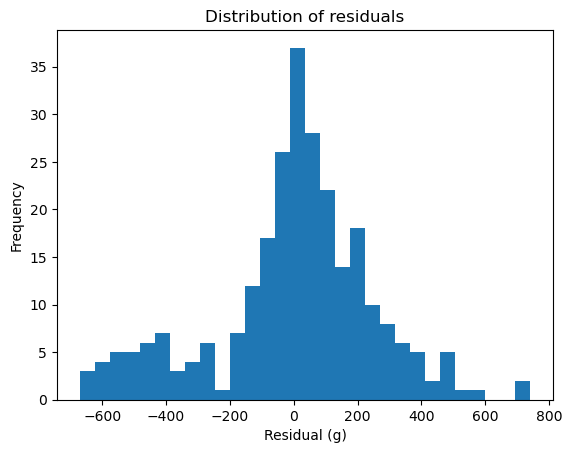

In [25]:
# Plot distribution of residuals
model.resid.plot(kind='hist', 
                 bins=30, 
                 title='Distribution of residuals', 
                 xlabel='Residual (g)')

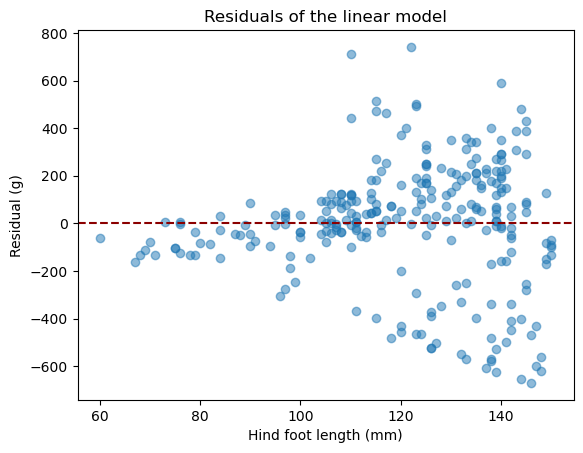

In [ ]:
# View how residuals vary with increasing hind foot size (mm)

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add residuals to axes
ax.scatter(juveniles_weight_hindft['hindft'], model.resid, alpha=0.5)

# Add reference line at 0
ax.axhline(0, color='darkred', linestyle='--')

# Update axes
ax.set_title('Residuals of the linear model')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Residual (g)')

# Display figure
plt.show()

## Conclusions:

1. Spread increases w/ hind foot length (mm)
2. Residuals are not centered on 0 for all hind foot (mm) values
3. For larger hind foot (mm) the residuals split into two groups (above and below 0)